# MSS-04 Sheet 1 — Exercise 2: Perceptron

Advanced Programming — Technische Hochschule Deggendorf

- **a)** naive implementation with pure Python functions
- **b)** NumPy implementation with `np.dot()` and a decision-boundary plot
- **c)** object-oriented implementation as a `perceptron` class

Test data: OR, AND and NAND.

## a) Naive implementation

In [1]:
def H(z):
    """Heaviside step function."""
    return 1 if z >= 0 else 0


def output(x1, x2, w1, w2, b):
    """Perceptron output for one 2-dimensional input."""
    return H(w1 * x1 + w2 * x2 + b)


def p_learn(X, Y, w1, w2, b, eta):
    """One pass of the perceptron learning algorithm."""
    for (x1, x2), y in zip(X, Y):
        error = y - output(x1, x2, w1, w2, b)
        w1 += eta * error * x1
        w2 += eta * error * x2
        b += eta * error
    return w1, w2, b

In [2]:
X = [[1, 1], [1, 0], [0, 1], [0, 0]]
Y_OR = [1, 1, 1, 0]

w1, w2, b = 0.0, 0.0, 0.0
eta = 0.1

print("before:", [output(x1, x2, w1, w2, b) for x1, x2 in X])
for epoch in range(10):
    w1, w2, b = p_learn(X, Y_OR, w1, w2, b, eta)
print("after: ", [output(x1, x2, w1, w2, b) for x1, x2 in X])
print("w1 =", w1, "w2 =", w2, "b =", b)

before: [1, 1, 1, 1]
after:  [1, 1, 1, 0]
w1 = 0.1 w2 = 0.1 b = -0.1


## b) NumPy implementation

In [3]:
import numpy as np
import matplotlib.pyplot as plt


def output(x, w, b):
    """Output for a single numpy input vector x."""
    return H(np.dot(x, w) + b)


def p_learn(X, Y, w, b, eta, epochs):
    """Train weights w and bias b for `epochs` passes over the data."""
    X = np.asarray(X, dtype=float)
    w = np.asarray(w, dtype=float).copy()
    for _ in range(epochs):
        for x, y in zip(X, Y):
            error = y - output(x, w, b)
            w = w + eta * error * x
            b = b + eta * error
    return w, b


def plot_decision_boundary(X, Y, w, b, title=""):
    """Plot the perceptron decision boundary sum(w_i*x_i) + b = 0."""
    X = np.asarray(X, dtype=float)
    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
    Z = w[0] * xx + w[1] * yy + b
    plt.figure(figsize=(4, 4))
    plt.contourf(xx, yy, Z, levels=[-np.inf, 0, np.inf],
                 colors=["#ffd6d6", "#d6e8ff"], alpha=0.8)
    plt.contour(xx, yy, Z, levels=[0], colors="black", linewidths=1.5)
    plt.scatter(X[:, 0], X[:, 1], c=Y, cmap="bwr", edgecolors="black", s=70, zorder=3)
    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.show()

weights: [0.1 0.1] bias: -0.1
predictions: [1, 1, 1, 0]


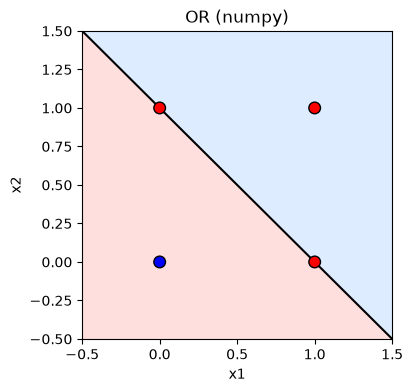

In [4]:
X = np.array([[1, 1], [1, 0], [0, 1], [0, 0]])
Y_OR = np.array([1, 1, 1, 0])

w, b = p_learn(X, Y_OR, np.zeros(2), 0.0, eta=0.1, epochs=20)
print("weights:", w, "bias:", b)
print("predictions:", [output(x, w, b) for x in X])
plot_decision_boundary(X, Y_OR, w, b, "OR (numpy)")

## c) Object-oriented implementation

In [5]:
class perceptron:
    def __init__(self, n_inputs):
        self.n_inputs = n_inputs
        self.weights = np.zeros(n_inputs)
        self.bias = 0.0

    def out(self, X):
        """Return the outputs for all input vectors in X."""
        return np.array([H(np.dot(x, self.weights) + self.bias) for x in X])

    def learn(self, data_learn, eta, epochs):
        """Train on data_learn = list(zip(X, Y))."""
        for _ in range(epochs):
            for x, y in data_learn:
                error = y - H(np.dot(x, self.weights) + self.bias)
                self.weights = self.weights + eta * error * x
                self.bias = self.bias + eta * error

    def plot_decision_boundary(self, X, Y, title=""):
        plot_decision_boundary(X, Y, self.weights, self.bias, title)

OR: weights=[0.1 0.1], bias=-0.10, predictions=[1 1 1 0]


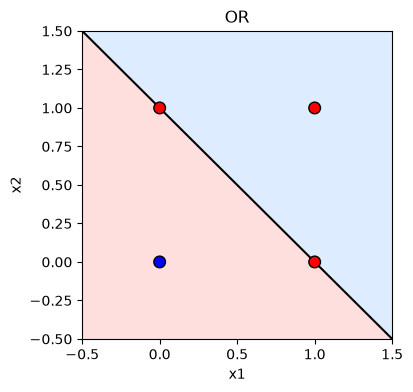

AND: weights=[0.1 0.2], bias=-0.20, predictions=[1 0 0 0]


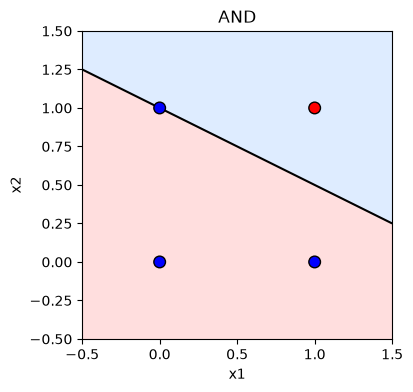

NAND: weights=[-0.1 -0.2], bias=0.20, predictions=[0 1 1 1]


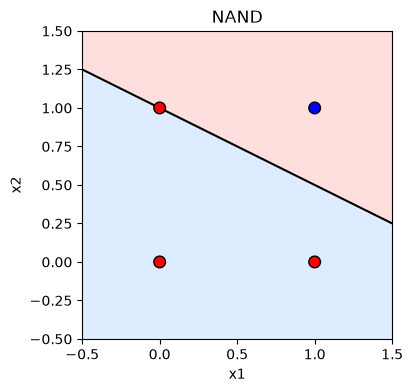

In [6]:
X = np.array([[1, 1], [1, 0], [0, 1], [0, 0]])
datasets = {
    "OR":   np.array([1, 1, 1, 0]),
    "AND":  np.array([1, 0, 0, 0]),
    "NAND": np.array([0, 1, 1, 1]),
}

for name, Y in datasets.items():
    p = perceptron(n_inputs=2)
    p.learn(list(zip(X, Y)), eta=0.1, epochs=20)
    print(f"{name}: weights={p.weights}, bias={p.bias:.2f}, predictions={p.out(X)}")
    p.plot_decision_boundary(X, Y, name)